https://www.youtube.com/watch?v=NKHQiN-08S8&t=6s

In [43]:
import pandas_datareader.data as web

In [44]:
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model
from scipy import stats
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [45]:
start = datetime(2015,1,1)
end = datetime(2023, 1, 1)

In [46]:
import yfinance as yf

#yf.pdr_override()

# Now data.DataReader will route through yfinance
raw_data = yf.download("AAPL", start=start, end=end)


[*********************100%***********************]  1 of 1 completed


In [47]:
raw_data.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2015-01-02,24.171762,24.638262,23.734004,24.627207,212818400
2015-01-05,23.490795,24.021411,23.305080,23.941819,257142000
2015-01-06,23.493006,23.751680,23.132628,23.554911,263188400
2015-01-07,23.822435,23.921925,23.590290,23.700835,160423600
2015-01-08,24.737745,24.795229,24.032468,24.149647,237458000


In [48]:
returns = 100 * raw_data['Close'].pct_change().dropna()

In [49]:
returns.head()

Ticker,AAPL
Date,
2015-01-05,-2.817202
2015-01-06,0.009411
2015-01-07,1.402246
2015-01-08,3.842218
2015-01-09,0.107242


Text(0, 0.5, 'returns')

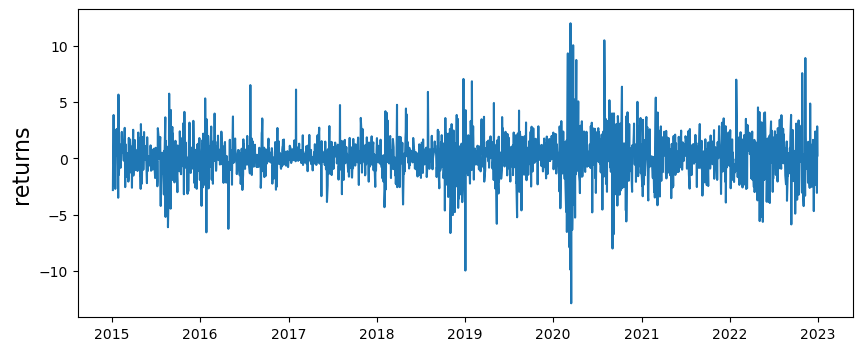

In [50]:
plt.figure(figsize=(10,4))
plt.plot(returns)
plt.ylabel('returns', fontsize= 16)

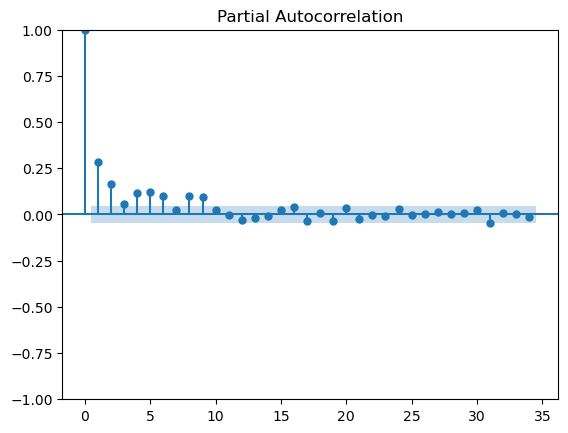

In [51]:
plot_pacf(returns**2)
plt.show()

In [52]:
model = arch_model(returns, p=2,q=2)

In [53]:
model_fit = model.fit()

Iteration:      1,   Func. Count:      8,   Neg. LLF: 11722.25100914139
Iteration:      2,   Func. Count:     18,   Neg. LLF: 2085214.7850050686
Iteration:      3,   Func. Count:     27,   Neg. LLF: 4042.0892379291436
Iteration:      4,   Func. Count:     35,   Neg. LLF: 4004.127950920658
Iteration:      5,   Func. Count:     43,   Neg. LLF: 5337.827208916267
Iteration:      6,   Func. Count:     52,   Neg. LLF: 3975.9493407782843
Iteration:      7,   Func. Count:     61,   Neg. LLF: 3982.1235001165587
Iteration:      8,   Func. Count:     69,   Neg. LLF: 3933.243244212451
Iteration:      9,   Func. Count:     77,   Neg. LLF: 3919.306780335851
Iteration:     10,   Func. Count:     84,   Neg. LLF: 3920.123677789136
Iteration:     11,   Func. Count:     92,   Neg. LLF: 3919.245690004181
Iteration:     12,   Func. Count:     99,   Neg. LLF: 3919.238608073274
Iteration:     13,   Func. Count:    106,   Neg. LLF: 3919.2330604348626
Iteration:     14,   Func. Count:    113,   Neg. LLF: 3919.

In [54]:
model_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                     Constant Mean - GARCH Model Results                      
==============================================================================
Dep. Variable:                   AAPL   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3919.21
Distribution:                  Normal   AIC:                           7850.43
Method:            Maximum Likelihood   BIC:                           7884.07
                                        No. Observations:                 2013
Date:                Thu, Oct 22 2026   Df Residuals:                     2012
Time:                        14:37:33   Df Model:                            1
                               Mean Model                               
========================================================================
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.1782  3.719e-02      4.792  1.652e-06 [  0.105,  0.251]
                             Volatility Model                             
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.1622      0.134      1.209      0.227   [ -0.101,  0.425]
alpha[1]       0.1116  3.385e-02      3.297  9.767e-04 [4.526e-02,  0.178]
alpha[2]       0.0152      0.115      0.132      0.895   [ -0.211,  0.241]
beta[1]        0.8286      0.750      1.104      0.270   [ -0.642,  2.299]
beta[2]    1.6134e-15      0.620  2.602e-15      1.000   [ -1.215,  1.215]
==========================================================================

Covariance estimator: robust
"""

alpha correspondence to lag version and beta correspondence to the volatility

try GARCH(1,1)

In [55]:
model = arch_model(returns, p=1,q=1)

In [56]:
model_fit = model.fit()

Iteration:      1,   Func. Count:      6,   Neg. LLF: 12654.28772498589
Iteration:      2,   Func. Count:     16,   Neg. LLF: 135675716968.1482
Iteration:      3,   Func. Count:     24,   Neg. LLF: 5556.08033918862
Iteration:      4,   Func. Count:     31,   Neg. LLF: 4575.64318888898
Iteration:      5,   Func. Count:     38,   Neg. LLF: 3920.646627117336
Iteration:      6,   Func. Count:     44,   Neg. LLF: 3919.353172244152
Iteration:      7,   Func. Count:     49,   Neg. LLF: 3919.3191128486847
Iteration:      8,   Func. Count:     54,   Neg. LLF: 3919.3171154615716
Iteration:      9,   Func. Count:     59,   Neg. LLF: 3919.316918516084
Iteration:     10,   Func. Count:     64,   Neg. LLF: 3919.316915544216
Iteration:     11,   Func. Count:     68,   Neg. LLF: 3919.3169155443857
Optimization terminated successfully    (Exit mode 0)
            Current function value: 3919.316915544216
            Iterations: 11
            Function evaluations: 68
            Gradient evaluations: 1

In [57]:
model_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                     Constant Mean - GARCH Model Results                      
==============================================================================
Dep. Variable:                   AAPL   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3919.32
Distribution:                  Normal   AIC:                           7846.63
Method:            Maximum Likelihood   BIC:                           7869.06
                                        No. Observations:                 2013
Date:                Thu, Oct 22 2026   Df Residuals:                     2012
Time:                        14:37:45   Df Model:                            1
                               Mean Model                               
========================================================================
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.1783  3.721e-02      4.792  1.651e-06 [  0.105,  0.251]
                             Volatility Model                             
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.1568  4.817e-02      3.255  1.134e-03 [6.238e-02,  0.251]
alpha[1]       0.1225  2.362e-02      5.186  2.151e-07 [7.620e-02,  0.169]
beta[1]        0.8342  2.796e-02     29.833 1.451e-195   [  0.779,  0.889]
==========================================================================

Covariance estimator: robust
"""

In [58]:
#forecasting using rolling forecast
rolling_predictions = []
test_size = 365


for i in range(test_size):
    train = returns[:-(test_size)-i]
    model = arch_model(train,p=1, q=1)
    model_fit = model.fit(disp = 'off')
    pred = model_fit.forecast(horizon =1)
    rolling_predictions.append(np.sqrt(pred.variance.values[-1,:][0]))

In [59]:
rolling_predictions = pd.Series(rolling_predictions, index= returns.index[-365:])

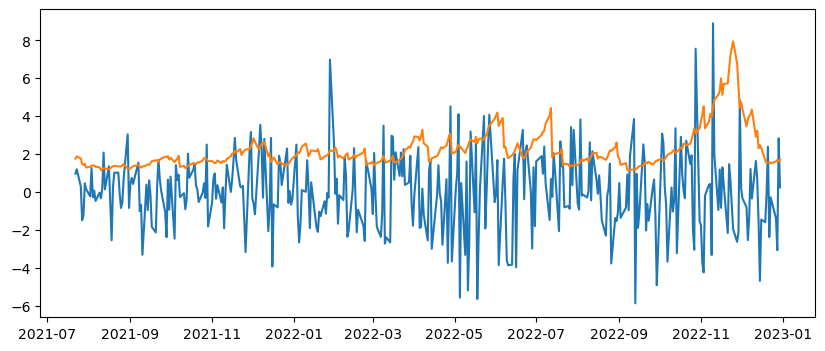

In [60]:
plt.figure(figsize =(10,4))
true, = plt.plot(returns[-365:])
preds, = plt.plot(rolling_predictions)

Applying model

In [62]:
train = returns
model = arch_model(train, p=1, q=1)
model_fit = model.fit(disp = 'off')

In [65]:
pred = model_fit.forecast(horizon=15)
future_dates = [returns.index[-1] + timedelta(days =i) for i in range (1, 16)]
pred = pd.Series(np.sqrt(pred.variance.values[-1,:]), index = future_dates)

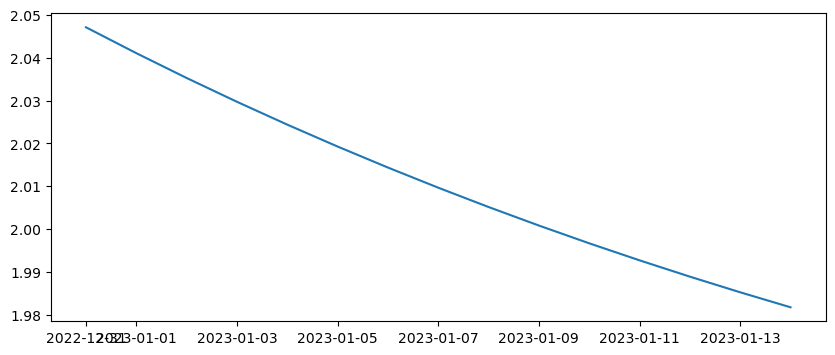

In [66]:
plt.figure(figsize = (10,4))
plt.plot(pred)